# Sustainability Impact Analysis for Intel
**Author:** Tina Marie Wilken  
**Date:** October 4, 2026  
**Project Type:** Capstone  
**Course/Program:** Coding for Data: Data Wrangling with SQL   
**Tools:** SQLPad  
**Status:** Complete / Validated    

---

## 1. Executive Summary
### Core Insight:
Intel’s device repurposing program processed 601,740 devices in 2024, mitigating 6,768 metric tons of $\text{CO}_2$ emissions and conserving approximately 15.5 GWh of energy. While 72.6% of program throughput consists of newer equipment ($\le 3$ years old), older hardware yields over double the environmental return per unit (49.73 kWh saved/device vs. 25.74 kWh baseline).  

### Business Context & Problem Statement
This project audits program effectiveness across device categories, operational age tiers, and regional electrical grid intensities to deliver a prioritized allocation framework for Intel’s global sustainability efforts.

### Key Business Question
Which device categories yield the highest net environmental return per unit, and how should Intel prioritize intake and resource allocation in its repurposing program?

### Primary Metric/KPI
Net Avoided Emissions ($\text{kg CO}_2\text{e}$) per repurposed unit.

### Stakeholders
Intel Sustainability Team

---

## 2. Data Sourcing & Architecture
### Data Source
Alvarez, R. (2026). Intel [Data set]. Coding for Data, Global Career Accelerators. https://globalcareeraccelerator.org/

### Data Set Description
The dataset contains 601,740 records tracking repurposed laptops and desktops from 2024 across North America, Europe, and Asia, detailing hardware specifications alongside annual energy savings and avoided $\text{CO}_2$ emissions. There are two tables included in the dataset, `intel.device_data` and `intel.impact_data`

| Table | Scope of Record | Primary Key | Record Count | Key Fields |
| :--- | :--- | :--- | :--- | :--- |
| `intel.device_data` | device profile data | `device_id` | 539,579 | `device_id`, `device_type`, `model_year` |
| `intel.impact_data` | device repurposing impact record | `impact_id` | 601,740 | `impact_id`, `device_id`, `usage_purpose`, `power_consumption`, `energy_savings_yr`, `co2_saved_kg_yr`, `recycling_rate`, `region` |

### Data Integrity & Governance
#### Data Governance, Ethics, & Privacy
- **Confidentiality & Provenance:** The dataset was provisioned via the Global Career Accelerator to mirror the schema, distributions, and relational structure of Intel’s enterprise sustainability data while preserving organizational confidentiality and proprietary manufacturing IP.
- **Simulated Scope:** This analysis uses a modeled dataset based on 2024 operational workflows. It is designed as an illustrative business case study and does not represent actual internal data or proprietary Intel operations.
- **PII Governance:** Hardware and deployment records exclude all personal user details, using strictly pseudonymized primary keys.

#### Analytical Limitations & Assumptions
- **Estimated Metrics:** The numbers for energy savings (`energy_savings_yr`) and carbon savings (`co2_saved_kg_yr`) are modeled estimates rather than live measurements from physical electric meters.
- **Unit Conversions:** Carbon savings were originally recorded in kilograms, so I converted them to metric tons by dividing by 1,000 to match standard environmental reporting formats.
- **Missing Cost Data:** The dataset does not include financial figures (*such as device intake costs, repair, labor expenses, or scrap values*) meaning this project focuses entirely on environmental impact rather than financial profit or cost-effectiveness.

---

## 3. Data Integrity Checks & Validation
- **Quality Audit:** Joined the `intel.device_data` and `intel.impact_data` tables on `device_id` and verified all 601,740 rows matched up properly without losing any records.
- **Cleaning Pipeline:** Checked for missing data to confirm there were no null values in `model_year`, and confirmed that all entries for device types (`Laptop`, `Desktop`) and regions (`North America`, `Europe`, `Asia`) were valid and consistent.
- **Feature Engineerng:** Calculated `device_age` by subtracting each device's `model_year` from 2024, then grouped them into three age categories: `newer` (3 years or less), `mid-age` (4 to 6 years), and `older` (more than 6 years).
- **Validation Check:** Reviewed the calculated `device_age` values to make sure there were no negative numbers or impossible future dates, and confirmed every single row was assigned to the correct age group with none left blank.

<br>

### Feature Pipeline & Age Bucketing
<pre style="background-color: #f8f9fa; color: #24292e; padding: 14px; border-radius: 6px; font-family: 'Consolas', 'Courier New', monospace; font-size: 13px; line-height: 1.5; border: 1px solid #e1e4e8;"><code><span style="color: #0000ff; font-weight: bold;">WITH</span> device_impact <span style="color: #0000ff; font-weight: bold;">AS</span> (
    <span style="color: #0000ff; font-weight: bold;">SELECT</span>
        a.*,
        b.*,
        (<span style="color: #22863a;">2024</span> - model_year) <span style="color: #0000ff; font-weight: bold;">AS</span> device_age
    <span style="color: #0000ff; font-weight: bold;">FROM</span> intel.device_data <span style="color: #0000ff; font-weight: bold;">AS</span> a 
    <span style="color: #0000ff; font-weight: bold;">INNER JOIN</span> intel.impact_data <span style="color: #0000ff; font-weight: bold;">AS</span> b 
        <span style="color: #0000ff; font-weight: bold;">ON</span> a.device_id = b.device_id
)
<span style="color: #0000ff; font-weight: bold;">SELECT</span>
    model_year,
    <span style="color: #0000ff; font-weight: bold;">CASE</span> 
        <span style="color: #0000ff; font-weight: bold;">WHEN</span> <span style="color: #22863a;">2024</span> - model_year &lt;= <span style="color: #22863a;">3</span> <span style="color: #0000ff; font-weight: bold;">THEN</span> <span style="color: #d73a49;">'newer'</span>
        <span style="color: #0000ff; font-weight: bold;">WHEN</span> <span style="color: #22863a;">2024</span> - model_year &lt;= <span style="color: #22863a;">6</span> <span style="color: #0000ff; font-weight: bold;">THEN</span> <span style="color: #d73a49;">'mid-age'</span>
        <span style="color: #0000ff; font-weight: bold;">ELSE</span> <span style="color: #d73a49;">'older'</span>
    <span style="color: #0000ff; font-weight: bold;">END</span> <span style="color: #0000ff; font-weight: bold;">AS</span> device_age_bucket
<span style="color: #0000ff; font-weight: bold;">FROM</span> device_impact;</code></pre>

<br>

&emsp;Query Results  
&emsp;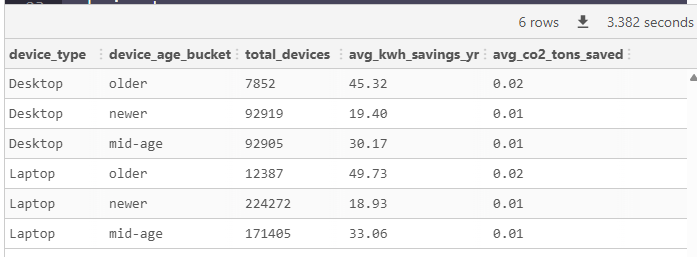  

<br>

### Null Audit
<pre style="background-color: #f8f9fa; color: #24292e; padding: 14px; border-radius: 6px; font-family: 'Consolas', 'Courier New', monospace; font-size: 13px; line-height: 1.5; border: 1px solid #e1e4e8;"><code><span style="color: #0000ff; font-weight: bold;">WITH</span> device_impact <span style="color: #0000ff; font-weight: bold;">AS</span> (
    <span style="color: #0000ff; font-weight: bold;">SELECT</span>
        a.*,
        b.*
    <span style="color: #0000ff; font-weight: bold;">FROM</span> intel.device_data <span style="color: #0000ff; font-weight: bold;">AS</span> a 
    <span style="color: #0000ff; font-weight: bold;">INNER JOIN</span> intel.impact_data <span style="color: #0000ff; font-weight: bold;">AS</span> b 
        <span style="color: #0000ff; font-weight: bold;">ON</span> a.device_id = b.device_id
)
<span style="color: #0000ff; font-weight: bold;">SELECT</span> *
<span style="color: #0000ff; font-weight: bold;">FROM</span> device_impact
<span style="color: #0000ff; font-weight: bold;">WHERE</span> model_year <span style="color: #0000ff; font-weight: bold;">IS NULL</span>;</code></pre>

<br>

&emsp;Query Results  
&emsp;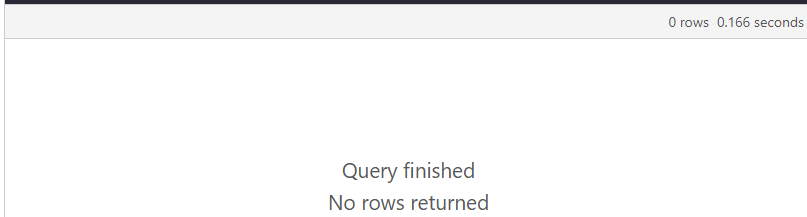

---

## 4. Analysis

### Macro Environmental Analysis
**Question:** What is the average estimated energy savings (kWh) from repurposed devices per year, and the total $\text{CO}_2$ emissions saved (in tons) from repurposed devices?

**My Approach:** I used `COUNT()` function for the column `device_age` to create a new column aliased as `total_devices`. I used the `ROUND()` and aggregate functions to calculate the average device age and average kWh saved per year. $\text{CO}_2$ is measured in kg. I used arithmetic operations to divide by 1000 to get a value in tons. I used the `ROUND()` function to two decimal places for a cleaner output.  

<pre style="background-color: #f8f9fa; color: #24292e; padding: 14px; border-radius: 6px; font-family: 'Consolas', 'Courier New', monospace; font-size: 13px; line-height: 1.5; border: 1px solid #e1e4e8;"><code><span style="color: #0000ff; font-weight: bold;">WITH</span> device_impact <span style="color: #0000ff; font-weight: bold;">AS</span> (
    <span style="color: #0000ff; font-weight: bold;">SELECT</span>
        a.*,
        b.*,
        (<span style="color: #22863a;">2024</span> - model_year) <span style="color: #0000ff; font-weight: bold;">AS</span> device_age
    <span style="color: #0000ff; font-weight: bold;">FROM</span> intel.device_data <span style="color: #0000ff; font-weight: bold;">AS</span> a 
    <span style="color: #0000ff; font-weight: bold;">INNER JOIN</span> intel.impact_data <span style="color: #0000ff; font-weight: bold;">AS</span> b 
        <span style="color: #0000ff; font-weight: bold;">ON</span> a.device_id = b.device_id
)
<span style="color: #0000ff; font-weight: bold;">SELECT</span>
    <span style="color: #b08800; font-weight: bold;">COUNT</span>(device_age) <span style="color: #0000ff; font-weight: bold;">AS</span> total_devices,
    <span style="color: #b08800; font-weight: bold;">ROUND</span>(<span style="color: #b08800; font-weight: bold;">AVG</span>(device_age), <span style="color: #22863a;">2</span>) <span style="color: #0000ff; font-weight: bold;">AS</span> avg_device_age,
    <span style="color: #b08800; font-weight: bold;">ROUND</span>(<span style="color: #b08800; font-weight: bold;">AVG</span>(energy_savings_yr), <span style="color: #22863a;">2</span>) <span style="color: #0000ff; font-weight: bold;">AS</span> avg_kWh_savings_yr,
    <span style="color: #b08800; font-weight: bold;">ROUND</span>(<span style="color: #b08800; font-weight: bold;">SUM</span>(co2_saved_kg_yr / <span style="color: #22863a;">1000</span>), <span style="color: #22863a;">2</span>) <span style="color: #0000ff; font-weight: bold;">AS</span> ttl_CO2_tons_saved
<span style="color: #0000ff; font-weight: bold;">FROM</span> device_impact;</code></pre>

<br>

Query Results  
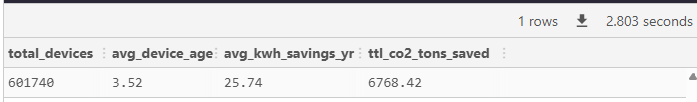

<br>

**Key Observation:**
The repurposing initiatives in 2024 avoided 6,768.42 metric tons of $\text{CO}_2$. This has roughly the same impact as:
- 10.1 GWh of avoided electricity, matching the annual energy demand of 970 U.S. homes.
- Offsetting the emissions from 1,580 gasoline-powered passenger vehicles for a full operational year.

At an average savings of 25.74 kWh per device, Intel saved the equivalent annual electricity consumption of approximately 1,489 average U.S. homes.

### Age vs. Impact Distribution
**Question:** Which device contributes the most to energy savings and $\text{CO}_2$ reduction?  

**My Approach:** From the previous query I kept the `total_devices` and `avg_kWh_savings_yr` columns and cleared the others. I added column `device_type` and an aggregate column using `ROUND()` (*to four decimal places*) and `AVG()` to calculate the average $\text{CO}_2$ saved per year. Then used `GROUP BY` and `ORDER BY` to organize the data by device type.

<pre style="background-color: #f8f9fa; color: #24292e; padding: 14px; border-radius: 6px; font-family: 'Consolas', 'Courier New', monospace; font-size: 13px; line-height: 1.5; border: 1px solid #e1e4e8;"><code><span style="color: #0000ff; font-weight: bold;">WITH</span> device_impact <span style="color: #0000ff; font-weight: bold;">AS</span> (
    <span style="color: #0000ff; font-weight: bold;">SELECT</span>
        a.*,
        b.*,
        (<span style="color: #22863a;">2024</span> - model_year) <span style="color: #0000ff; font-weight: bold;">AS</span> device_age
    <span style="color: #0000ff; font-weight: bold;">FROM</span> intel.device_data <span style="color: #0000ff; font-weight: bold;">AS</span> a 
    <span style="color: #0000ff; font-weight: bold;">INNER JOIN</span> intel.impact_data <span style="color: #0000ff; font-weight: bold;">AS</span> b 
        <span style="color: #0000ff; font-weight: bold;">ON</span> a.device_id = b.device_id
)
<span style="color: #0000ff; font-weight: bold;">SELECT</span>
    device_type,
    <span style="color: #b08800; font-weight: bold;">COUNT</span>(device_type) <span style="color: #0000ff; font-weight: bold;">AS</span> total_devices,
    <span style="color: #b08800; font-weight: bold;">ROUND</span>(<span style="color: #b08800; font-weight: bold;">AVG</span>(energy_savings_yr), <span style="color: #22863a;">2</span>) <span style="color: #0000ff; font-weight: bold;">AS</span> avg_kWh_savings_yr,
    <span style="color: #b08800; font-weight: bold;">ROUND</span>((<span style="color: #b08800; font-weight: bold;">AVG</span>(co2_saved_kg_yr / <span style="color: #22863a;">1000</span>)), <span style="color: #22863a;">2</span>) <span style="color: #0000ff; font-weight: bold;">AS</span> avg_CO2_tons_saved
<span style="color: #0000ff; font-weight: bold;">FROM</span> device_impact
<span style="color: #0000ff; font-weight: bold;">GROUP BY</span> device_type
<span style="color: #0000ff; font-weight: bold;">ORDER BY</span> device_type <span style="color: #0000ff; font-weight: bold;">DESC</span>;</code></pre>

<br>

Query Results  
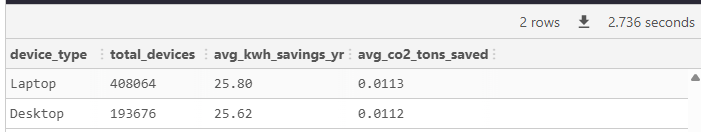

<br>

**Key Observation:**  
Both laptop and desktop devices save approximately the same amount of CO₂, with laptops edging out higher by $\frac{1}{10000}$ at an average in tons saved. Laptops save more than desktops as far as the average kWh saved per year at 25.8 versus 25.62 for desktops.  

Possible Contributing Factors:  
- Laptops are designed using lower-powered processors, displays, etc. for preserving battery life.
- Laptops and desktops may not be used for the same amount of workloads.
- Device age and hardware specifications for both devices could contribute to the differences of savings as well.

**Question:** Which device age bucket has the highest average energy saved?  

**My Approach:** I used a `CASE WHEN` expression to sort into three age buckets (`newer` $\le$ 3 years, `mid-age` $\le$ 6 years, `older` > 6 years) and created an alias for the column as `device_age_bucket`.  I used the `COUNT()` function to create the aliased column `total_devices`. Two aggregate columns were created using `ROUND()` and `AVG()` function for calculating the average energy saved per year and average $\text{CO}_2$ saved per year. Query was grouped and ordered by `device_type` and `device_age_bucket` in descending order.

<pre style="background-color: #f8f9fa; color: #24292e; padding: 14px; border-radius: 6px; font-family: 'Consolas', 'Courier New', monospace; font-size: 13px; line-height: 1.5; border: 1px solid #e1e4e8;"><code><span style="color: #0000ff; font-weight: bold;">WITH</span> device_impact <span style="color: #0000ff; font-weight: bold;">AS</span> (
    <span style="color: #0000ff; font-weight: bold;">SELECT</span>
        a.*,
        b.*,
        (<span style="color: #22863a;">2024</span> - model_year) <span style="color: #0000ff; font-weight: bold;">AS</span> device_age,
        <span style="color: #0000ff; font-weight: bold;">CASE</span> 
            <span style="color: #0000ff; font-weight: bold;">WHEN</span> <span style="color: #22863a;">2024</span> - model_year &lt;= <span style="color: #22863a;">3</span> <span style="color: #0000ff; font-weight: bold;">THEN</span> <span style="color: #d73a49;">'newer'</span>
            <span style="color: #0000ff; font-weight: bold;">WHEN</span> <span style="color: #22863a;">2024</span> - model_year &lt;= <span style="color: #22863a;">6</span> <span style="color: #0000ff; font-weight: bold;">THEN</span> <span style="color: #d73a49;">'mid-age'</span>
            <span style="color: #0000ff; font-weight: bold;">ELSE</span> <span style="color: #d73a49;">'older'</span>
        <span style="color: #0000ff; font-weight: bold;">END</span> <span style="color: #0000ff; font-weight: bold;">AS</span> device_age_bucket
    <span style="color: #0000ff; font-weight: bold;">FROM</span> intel.device_data <span style="color: #0000ff; font-weight: bold;">AS</span> a 
    <span style="color: #0000ff; font-weight: bold;">INNER JOIN</span> intel.impact_data <span style="color: #0000ff; font-weight: bold;">AS</span> b 
        <span style="color: #0000ff; font-weight: bold;">ON</span> a.device_id = b.device_id
)
<span style="color: #0000ff; font-weight: bold;">SELECT</span>
    device_type,
    device_age_bucket,
    <span style="color: #b08800; font-weight: bold;">COUNT</span>(device_type) <span style="color: #0000ff; font-weight: bold;">AS</span> total_devices,
    <span style="color: #b08800; font-weight: bold;">ROUND</span>(<span style="color: #b08800; font-weight: bold;">AVG</span>(energy_savings_yr), <span style="color: #22863a;">2</span>) <span style="color: #0000ff; font-weight: bold;">AS</span> avg_kWh_savings_yr,
    <span style="color: #b08800; font-weight: bold;">ROUND</span>((<span style="color: #b08800; font-weight: bold;">AVG</span>(co2_saved_kg_yr / <span style="color: #22863a;">1000</span>)), <span style="color: #22863a;">4</span>) <span style="color: #0000ff; font-weight: bold;">AS</span> avg_CO2_tons_saved
<span style="color: #0000ff; font-weight: bold;">FROM</span> device_impact
<span style="color: #0000ff; font-weight: bold;">GROUP BY</span> 
    device_type, 
    device_age_bucket
<span style="color: #0000ff; font-weight: bold;">ORDER BY</span> 
    device_type,
    device_age_bucket <span style="color: #0000ff; font-weight: bold;">DESC</span>;</code></pre>

<br>

Query Results  
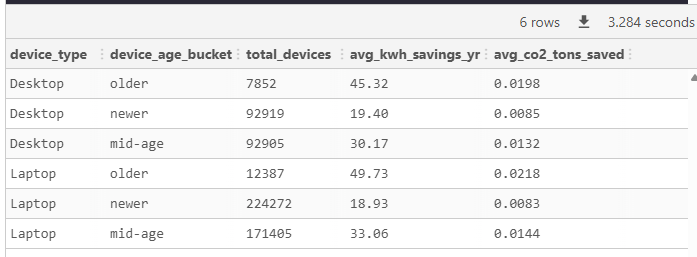

<br>

**Key Observation:**  
Newer devices ($\le$ 3 years) make up the largest share of repurposed equipment, with laptops at 224,272 and desktops at 92,919. Older devices (> 6 years) have the smallest share, totaling 12,387 for laptops and 7,852 for desktops.  

Despite having the lowest counts, older devices yield the highest savings in both energy and $\text{CO}_2$ emissions per unit. Older laptops save an average of 49.73 kWh per year and 0.0218 tons of $\text{CO}_2$, while older desktops save an average of 45.32 kWh per year and 0.0198 tons of $\text{CO}_2$.  

Possible Contributing Factors:  
- Older hardware operates on less energy-efficient infrastructures, so replacing or retiring them avoids a higher baseline of power consumption.
- Workload demands and how components degrade over time are contributing factors that could widen the savings gap between newer and older devices.

### Regional Grid Intensity Analysis
**Question:** How does the carbon intensity of electricity in each region impact the total $\text{CO}_2$ savings from repurposed devices? Are there regions where repurposing leads to significantly higher environmental benefits?  

**My Approach:** I altered my previous query by replacing the `device_age_bucket` column with the `region` column. The `region` column also replaced `device_age_bucket` when grouping and ordering in descension.

<pre style="background-color: #f8f9fa; color: #24292e; padding: 14px; border-radius: 6px; font-family: 'Consolas', 'Courier New', monospace; font-size: 13px; line-height: 1.5; border: 1px solid #e1e4e8;"><code><span style="color: #0000ff; font-weight: bold;">WITH</span> device_impact <span style="color: #0000ff; font-weight: bold;">AS</span> (
    <span style="color: #0000ff; font-weight: bold;">SELECT</span>
        a.*,
        b.*,
        (<span style="color: #22863a;">2024</span> - model_year) <span style="color: #0000ff; font-weight: bold;">AS</span> device_age,
        <span style="color: #0000ff; font-weight: bold;">CASE</span> 
            <span style="color: #0000ff; font-weight: bold;">WHEN</span> <span style="color: #22863a;">2024</span> - model_year &lt;= <span style="color: #22863a;">3</span> <span style="color: #0000ff; font-weight: bold;">THEN</span> <span style="color: #d73a49;">'newer'</span>
            <span style="color: #0000ff; font-weight: bold;">WHEN</span> <span style="color: #22863a;">2024</span> - model_year &lt;= <span style="color: #22863a;">6</span> <span style="color: #0000ff; font-weight: bold;">THEN</span> <span style="color: #d73a49;">'mid-age'</span>
            <span style="color: #0000ff; font-weight: bold;">ELSE</span> <span style="color: #d73a49;">'older'</span>
        <span style="color: #0000ff; font-weight: bold;">END</span> <span style="color: #0000ff; font-weight: bold;">AS</span> device_age_bucket
    <span style="color: #0000ff; font-weight: bold;">FROM</span> intel.device_data <span style="color: #0000ff; font-weight: bold;">AS</span> a 
    <span style="color: #0000ff; font-weight: bold;">INNER JOIN</span> intel.impact_data <span style="color: #0000ff; font-weight: bold;">AS</span> b 
        <span style="color: #0000ff; font-weight: bold;">ON</span> a.device_id = b.device_id
)
<span style="color: #0000ff; font-weight: bold;">SELECT</span>
    device_type,
    region,
    <span style="color: #b08800; font-weight: bold;">COUNT</span>(device_type) <span style="color: #0000ff; font-weight: bold;">AS</span> total_devices,
    <span style="color: #b08800; font-weight: bold;">ROUND</span>(<span style="color: #b08800; font-weight: bold;">AVG</span>(energy_savings_yr), <span style="color: #22863a;">2</span>) <span style="color: #0000ff; font-weight: bold;">AS</span> avg_kWh_savings_yr,
    <span style="color: #b08800; font-weight: bold;">ROUND</span>((<span style="color: #b08800; font-weight: bold;">AVG</span>(co2_saved_kg_yr / <span style="color: #22863a;">1000</span>)), <span style="color: #22863a;">4</span>) <span style="color: #0000ff; font-weight: bold;">AS</span> avg_CO2_tons_saved
<span style="color: #0000ff; font-weight: bold;">FROM</span> device_impact
<span style="color: #0000ff; font-weight: bold;">GROUP BY</span> 
    device_type, 
    region
<span style="color: #0000ff; font-weight: bold;">ORDER BY</span> 
    device_type,
    region;</code></pre>

<br>

Query Results  
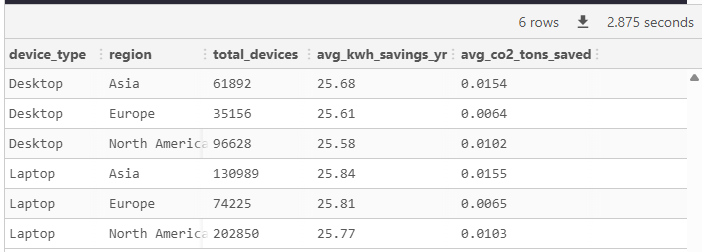

<br>

**Key Observations:**  
- Asia has the highest carbon intensity for both desktops and laptops at approximately 0.599 kg $\text{CO}_2$/kWh, followed by North America at approximately 0.398 to 0.399 kg $\text{CO}_2$/kWh, and Europe with the lowest at roughly 0.249 to 0.252 kg $\text{CO}_2$/kWh.
- Since electricity in Asia is significantly more carbon-heavy, saving a kilowatt an hour of energy there prevents more greenhouse gas emissions than saving the same kilowatt an hour in Europe.
- North America provides the second largest reduction, while Europe captures the smallest footprint benefit due to its cleaner energy grid combined with lower repurposed device counts.

| `device_type` | `region` | `carbon_intensity` |
| :--- | :--- | :--- |
| Desktop | Asia | (0.0154 t/25.68 kWh)*1000 = 0.599 kg CO₂/kWh |
| Desktop | Europe | (0.0064 t/25.61 kWh)*1000 = .249 kg CO₂/kWh |
| Desktop | North America | (0.0102 t/25.58 kWh)*1000 = .398 kg CO₂/kWh |
| Laptop | Asia | (0.0155 t/25.84 kWh)*1000 = .599 kg CO₂/kWh |
| Laptop | Europe | (0.0065 t/25.81 kWh)*1000 = .252 kg CO₂/kWh |
| Laptop | North America | (0.0103 t/25.77 kWh)*1000 = .399 kg CO₂/kWh |

---

## Insights
### Key Takeaways
1. Older equipment makes up a small share of repurposed equipment, but shows the greatest in energy and CO₂ savings.
2. Laptops provide a slightly higher average annual energy savings than desktops.
3. Regional carbon intensity influences the benefits of repurposing.
4. New devices are a substantial share of repurposed equipment, which means we don’t have to wait for the end-of-lifecycle stage of devices to create value.


---

## Business Recommendations & Next Steps
### Strategic Solutions
| Priority | Recommendation | Rationale |
| :--- | :--- | :--- |
| 1 | Repurpose devices in high-carbon grid regions (e.g. Asia) | To generate the fastest per-unit emissions reductions. |
| 2 | Target older, power-inefficient devices | Older units have the steepest efficiency losses and consume significantly more power. |
| 3 | Recondition laptops and newer assets | Laptops are a high-inventory item and high average annual energy savings. |

### Risk Factors & Limitations
- Lacked cost data for repairs, so ROI could not be confirmed. 
- Lack data on lifespan of repurposed devices.

### Next Steps
- Further analysis on total energy savings per device within each region.
- Collect data on repair cost data and run cost analysis.

---

## Appendix
### Skills Practiced in This Project
- Data cleaning and feature engineering
- Writing SQL joins, and aggregations
- Utilizing CTEs and CASE WHEN
- Communicating findings to a non-technical audience

### What I Learned
I learned the `ROUND()` function is useful in cleaning up output but you have to be careful not to abbreviate the decimal places too much. It could lead to less accurate data when using it to analyze differences. Moving forward, I'll start with four decimal places. CTEs are incredibly useful! I look forward to more practice with them.

### References & Acknowledgments
- Coding for Data: Data Wrangling with SQL, Global Career Accelerators. https://globalcareeraccelerator.org/

---

### Change Log
| Date (YYYY-MM-DD) | Version | Changed By | Change Description |
| :--- | :--- | :---| :--- |
| 2026-10-13 | 1.0 | Tina Marie Wilken | Initial draft: Migrated SQL capstone assignment from worksheet to Jupyter Notebook |